# Tumor Mutational Burden (TMB) Analysis with PyMut-Bio

This notebook demonstrates how to use the `calculate_tmb_analysis` method from PyMut-Bio to calculate Tumor Mutational Burden (TMB) and generate the corresponding analysis files.

## What is TMB?
Tumor Mutational Burden (TMB) is a measure of the number of mutations present in a tumor, normalized by the size of the interrogated genome. It is an important biomarker in oncology.


## Initial Setup


In [1]:
import os
from pyMut.input import read_maf

print('✅ Modules imported successfully')


✅ Modules imported successfully


## Load Example Data

For this example, you will need a MAF file. You can use your own data or download example data from TCGA.


In [2]:
maf_path = "../../../src/pyMut/data/examples/MAF/tcga_laml.maf.gz"  # Replace with the path to your MAF file

# Check if the file exists
if not os.path.exists(maf_path):
    print(f"❌ File not found: {maf_path}")
    print("📝 Please specify the correct path to your MAF file in the 'maf_path' variable")
    print("💡 You can download example data from TCGA or use your own data")
else:
    print(f'📂 Loading file: {maf_path}')
    py_mutation = read_maf(maf_path, assembly="37")
    
    print("✅ Data loaded successfully")
    print(f"📊 Data shape: {py_mutation.data.shape}")
    print(f"👥 Number of samples: {len(py_mutation.samples)}")
    print(f"🧬 First 3 samples: {py_mutation.samples[:3]}")


2026-10-13 14:51:31,720 | INFO | pyMut.input | Starting MAF reading: ../../../src/pyMut/data/examples/MAF/tcga_laml.maf.gz
2026-10-13 14:51:31,722 | INFO | pyMut.input | Loading from cache: ../../../src/pyMut/data/examples/MAF/.pymut_cache/tcga_laml.maf_8dc5feebdfe14cbc.parquet
2026-10-13 14:51:31,844 | INFO | pyMut.input | Cache loaded successfully in 0.12 seconds


📂 Loading file: ../../../src/pyMut/data/examples/MAF/tcga_laml.maf.gz
✅ Data loaded successfully
📊 Data shape: (2091, 216)
👥 Number of samples: 193
🧬 First 3 samples: ['TCGA-AB-2988', 'TCGA-AB-2869', 'TCGA-AB-3009']


## Explore Variant Classification Columns

Before running the TMB analysis, let's see what variant classification columns are available:


In [3]:
# Search for variant classification columns
import re

pattern = re.compile(r'^(gencode_\d+_)?variant[_]?classification$', flags=re.IGNORECASE)
variant_cols = [col for col in py_mutation.data.columns if pattern.match(col)]

print("🔍 Variant classification columns found:")
if variant_cols:
    for i, col in enumerate(variant_cols, 1):
        print(f"  {i}. {col}")
else:
    print("  ❌ No variant classification columns found")

# Show some columns that contain 'variant' in the name
variant_like_cols = [col for col in py_mutation.data.columns if 'variant' in col.lower()]
print(f"\n🔍 Columns containing 'variant' ({len(variant_like_cols)}):")
for col in variant_like_cols[:5]:  # Show only the first 5
    print(f"  • {col}")


🔍 Variant classification columns found:
  1. Variant_Classification

🔍 Columns containing 'variant' (2):
  • Variant_Classification
  • Variant_Type


## Run TMB Analysis

Now we will run the mutational burden analysis. The method will generate two files:
1. **TMB_analysis.tsv**: Per-sample analysis with mutation counts and normalized TMB
2. **TMB_statistics.tsv**: Global statistics (mean, median, quartiles, etc.)


In [4]:
# Create directory for results
output_dir = "results_tmb"
os.makedirs(output_dir, exist_ok=True)

print(f"📁 Output directory: {output_dir}")


📁 Output directory: results_tmb


In [5]:
# Run TMB analysis
print("🧬 Running mutational burden analysis...")
print("⏳ This may take a few moments...")

try:
    # Run TMB analysis with standard configuration for WES
    results = py_mutation.calculate_tmb_analysis(
        genome_size_bp=60456963,  # Standard size for WES
        output_dir=output_dir,
        save_files=True
    )
    
    print("✅ TMB analysis completed successfully!")
    
except Exception as e:
    print(f"❌ Error during TMB analysis: {e}")
    results = None


2026-10-13 14:51:53,767 | INFO | pyMut.analysis.mutation_burden | Auto-detected variant classification column: Variant_Classification


🧬 Running mutational burden analysis...
⏳ This may take a few moments...


2026-10-13 14:51:55,032 | INFO | pyMut.analysis.mutation_burden | TMB analysis saved to: results_tmb/TMB_analysis.tsv
2026-10-13 14:51:55,034 | INFO | pyMut.analysis.mutation_burden | TMB statistics saved to: results_tmb/TMB_statistics.tsv
2026-10-13 14:51:55,035 | INFO | pyMut.analysis.mutation_burden | Analyzed 193 samples with 2091 total mutations
2026-10-13 14:51:55,036 | INFO | pyMut.analysis.mutation_burden | TMB ANALYSIS SUMMARY
2026-10-13 14:51:55,037 | INFO | pyMut.analysis.mutation_burden | • Total samples analyzed: 193
2026-10-13 14:51:55,038 | INFO | pyMut.analysis.mutation_burden | • Average non-synonymous mutations per sample: 9.0
2026-10-13 14:51:55,039 | INFO | pyMut.analysis.mutation_burden | • Average TMB: 0.148438 mutations/Mb
2026-10-13 14:51:55,040 | INFO | pyMut.analysis.mutation_burden | • Median TMB: 0.148866 mutations/Mb
2026-10-13 14:51:55,041 | INFO | pyMut.analysis.mutation_burden | • Sample with highest TMB: TCGA-AB-3009
2026-10-13 14:51:55,041 | INFO | pyM

✅ TMB analysis completed successfully!


## Explore Results


In [6]:
if results:
    # Get the results DataFrames
    analysis_df = results['analysis']
    statistics_df = results['statistics']
    
    print("📊 TMB ANALYSIS RESULTS")
    print("=" * 50)
    print(f"👥 Samples analyzed: {len(analysis_df)}")
    print(f"📈 Metrics calculated: {len(statistics_df)}")
    
    # Show the first rows of the per-sample analysis
    print("\n🔍 First 5 samples from analysis:")
    print("-" * 40)
    display(analysis_df.head())
    
else:
    print("❌ Could not obtain analysis results")


📊 TMB ANALYSIS RESULTS
👥 Samples analyzed: 193
📈 Metrics calculated: 2

🔍 First 5 samples from analysis:
----------------------------------------


,Tumor_Sample_Barcode,total,total_perMB,total_perMB_log
0,TCGA-AB-2903,0,0.000000,-inf
1,TCGA-AB-2848,1,0.016541,-1.781446
2,TCGA-AB-2946,1,0.016541,-1.781446
3,TCGA-AB-2933,1,0.016541,-1.781446
4,TCGA-AB-2982,1,0.016541,-1.781446


## Global Statistics


In [7]:
if results:
    print("📈 TMB GLOBAL STATISTICS")
    print("=" * 40)
    display(statistics_df)
    
    # Show key statistics
    print("\n🎯 KEY STATISTICS:")
    print("-" * 30)
    
    # Normalized TMB per MB
    if "total_perMB" in statistics_df["Metric"].values:
        tmb_stats = statistics_df[statistics_df["Metric"] == "total_perMB"].iloc[0]
        print("🧬 Normalized TMB (mutations/Mb):")
        print(f"   • Mean: {tmb_stats['Mean']:.4f} mutations/Mb")
        print(f"   • Median: {tmb_stats['Median']:.4f} mutations/Mb")
        print(f"   • Range: {tmb_stats['Min']:.4f} - {tmb_stats['Max']:.4f} mutations/Mb")
    
    # Raw mutation count
    if "total" in statistics_df["Metric"].values:
        count_stats = statistics_df[statistics_df["Metric"] == "total"].iloc[0]
        print("\n🎯 Raw Mutation Counts:")
        print(f"   • Mean: {count_stats['Mean']:.2f} mutations")
        print(f"   • Median: {count_stats['Median']:.2f} mutations")
        print(f"   • Range: {count_stats['Min']:.0f} - {count_stats['Max']:.0f} mutations")


📈 TMB GLOBAL STATISTICS


,Metric,Count,Mean,Median,Min,Max,Q1,Q3,Std
0,total,193,8.974093,9.000000,0.0,34.000000,5.000000,12.000000,5.452862
1,total_perMB,193,0.148438,0.148866,0.0,0.562384,0.082703,0.198488,0.090194



🎯 KEY STATISTICS:
------------------------------
🧬 Normalized TMB (mutations/Mb):
   • Mean: 0.1484 mutations/Mb
   • Median: 0.1489 mutations/Mb
   • Range: 0.0000 - 0.5624 mutations/Mb

🎯 Raw Mutation Counts:
   • Mean: 8.97 mutations
   • Median: 9.00 mutations
   • Range: 0 - 34 mutations


## Important Notes

- **Genome size**: The parameter `genome_size_bp=60456963` corresponds to the standard size for Whole Exome Sequencing (WES). Adjust this value according to your sequencing type:
  - WES: ~60 Mb
  - WGS: ~3000 Mb
  - Targeted panel: specific panel size

- **Output files**: The TSV files are saved in the specified directory and contain:
  - `TMB_analysis.tsv`: Detailed per-sample analysis
  - `TMB_statistics.tsv`: Summary statistics of the dataset

- **Interpretation**: TMB values are expressed in mutations per megabase (mutations/Mb) and can be used as a biomarker for immunotherapy treatments.


## TCGA Cohort TMB Comparison (`tcga_compare` and `calculate_tcga_compare`)

You can benchmark this cohort's TMB against the ~33 TCGA reference cohorts bundled with `maftools`. The `tcga_compare()` function creates a publication-ready dotplot with cohort medians, while `calculate_tcga_compare()` computes the underlying statistical tables.

In [6]:
# Calculate comparison statistics
tcga_results = py_mutation.calculate_tcga_compare(
    cohort_name="LAML-TB",
    capture_size=50.0,
    save_files=False
)
display(tcga_results["median_mutation_burden"].head(10))

2026-10-13 14:52:03,177 | INFO | pyMut.analysis.mutation_burden | Auto-detected variant classification column: Variant_Classification
2026-10-13 14:52:04,362 | INFO | pyMut.analysis.mutation_burden | TMB ANALYSIS SUMMARY
2026-10-13 14:52:04,364 | INFO | pyMut.analysis.mutation_burden | • Total samples analyzed: 193
2026-10-13 14:52:04,364 | INFO | pyMut.analysis.mutation_burden | • Average non-synonymous mutations per sample: 9.0
2026-10-13 14:52:04,365 | INFO | pyMut.analysis.mutation_burden | • Average TMB: 0.179482 mutations/Mb
2026-10-13 14:52:04,365 | INFO | pyMut.analysis.mutation_burden | • Median TMB: 0.180000 mutations/Mb
2026-10-13 14:52:04,366 | INFO | pyMut.analysis.mutation_burden | • Sample with highest TMB: TCGA-AB-3009
2026-10-13 14:52:04,368 | INFO | pyMut.analysis.mutation_burden |   - TMB value: 0.680000 mutations/Mb
2026-10-13 14:52:04,370 | INFO | pyMut.analysis.mutation_burden | • Sample with lowest TMB: TCGA-AB-2903
2026-10-13 14:52:04,371 | INFO | pyMut.analysis

,Cohort,Cohort_Size,Median_Mutations
0,LAML-TB,192,0.180000
1,LAML,137,0.251397
2,PCPG,183,0.251397
3,THCA,499,0.279330
4,UVM,80,0.321229
5,TGCT,133,0.363128
6,THYM,123,0.391061
7,KICH,66,0.544693
8,ACC,92,0.712291
9,LGG,524,0.754190


2026-10-13 14:52:56,678 | INFO | pyMut.analysis.mutation_burden | Auto-detected variant classification column: Variant_Classification
2026-10-13 14:52:57,944 | INFO | pyMut.analysis.mutation_burden | TMB ANALYSIS SUMMARY
2026-10-13 14:52:57,946 | INFO | pyMut.analysis.mutation_burden | • Total samples analyzed: 193
2026-10-13 14:52:57,947 | INFO | pyMut.analysis.mutation_burden | • Average non-synonymous mutations per sample: 9.0
2026-10-13 14:52:57,948 | INFO | pyMut.analysis.mutation_burden | • Average TMB: 0.179482 mutations/Mb
2026-10-13 14:52:57,949 | INFO | pyMut.analysis.mutation_burden | • Median TMB: 0.180000 mutations/Mb
2026-10-13 14:52:57,950 | INFO | pyMut.analysis.mutation_burden | • Sample with highest TMB: TCGA-AB-3009
2026-10-13 14:52:57,952 | INFO | pyMut.analysis.mutation_burden |   - TMB value: 0.680000 mutations/Mb
2026-10-13 14:52:57,953 | INFO | pyMut.analysis.mutation_burden | • Sample with lowest TMB: TCGA-AB-2903
2026-10-13 14:52:57,955 | INFO | pyMut.analysis

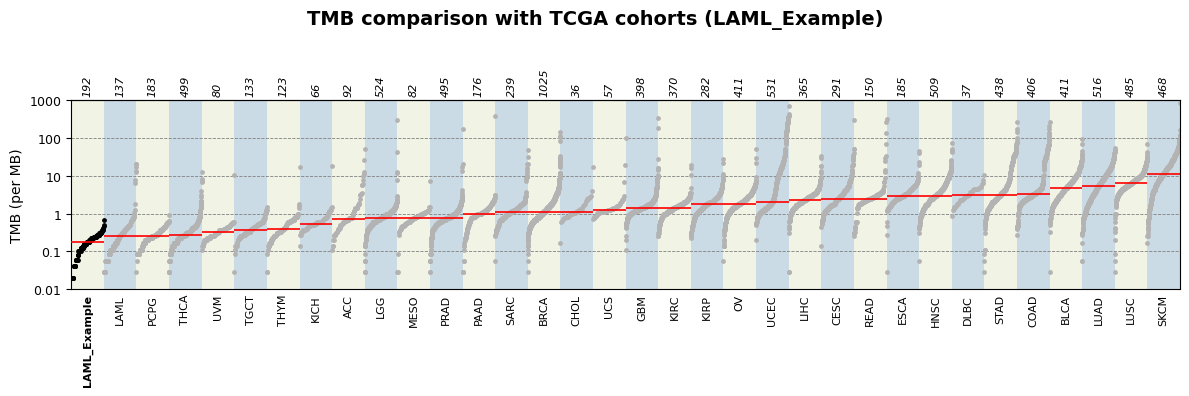

In [9]:
# Plot comparison against TCGA cohorts
fig = py_mutation.tcga_compare(
    cohort_name="LAML_Example",
    capture_size=50.0,
    logscale=True,
    figsize=(12, 4)
)
import matplotlib.pyplot as plt
fig